# GAM regression for student final grades

This standalone notebook fits a penalized **generalized additive model (GAM)** for student final grades. It follows the dataset, target, and 85/15 split used in Project.ipynb, and uses Guan-Ming's 22-predictor GAM specification: five continuous splines and factor terms for the remaining discrete and categorical predictors. One penalty is shared by the splines and another by the factor terms.

The analysis selects the two penalties by the lowest inner-CV mean RMSE and compares the GAM with a mean-only baseline and a fixed-settings random forest on the same outer folds. The held-out test partition is the same one already inspected in Project.ipynb, so its scores are corroborative rather than fresh independent confirmation.

Run from this notebook's folder, or from the parent project folder, with the **py3.14** environment containing PyGAM.

In [12]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
import pygam
import sklearn
from pygam import LinearGAM, f, s
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import KFold, train_test_split

SEED = 42
TEST_SIZE = 0.15
OUTER_SPLITS = 5
INNER_SPLITS = 5
BASE_LAMBDA_GRID = np.array([0.1, 1.0, 10.0, 100.0, 1_000.0, 10_000.0])
WIDE_LAMBDA_GRID = np.array([0.001, 0.1, 10.0, 1_000.0, 100_000.0])
TARGET = "final_grade_pct"

print("PyGAM:", pygam.__version__, "| scikit-learn:", sklearn.__version__)
print("Outer folds:", OUTER_SPLITS, "| inner folds:", INNER_SPLITS)

PyGAM: 0.12.0 | scikit-learn: 1.9.1
Outer folds: 5 | inner folds: 5


## Data preparation

Remove exact duplicate records, exclude student ID, survey date, grade class, and risk flag, and log-transform positive annual family income. As in Guan-Ming's GAM, `academic_year` and `family_income_bracket` are omitted from the predictor set. Grade class is used **only** to stratify the initial train/test split.


In [13]:
data_path = Path("student_grade_ses_dataset.csv")
if not data_path.exists():
    data_path = Path("ST5227-Course-Project") / data_path.name
assert data_path.exists(), f"Dataset not found: {data_path}"

df = pd.read_csv(data_path)
raw_n = len(df)
df = df.drop_duplicates().set_index("student_id")
assert df.index.is_unique
assert df[TARGET].notna().all()
assert (df["annual_family_income_inr"].dropna() > 0).all()
df["log_income"] = np.log(df["annual_family_income_inr"])
df = df.drop(columns="annual_family_income_inr")

CONTINUOUS_COLS = [
    "distance_to_school_km", "study_hours_per_week",
    "attendance_rate_pct", "previous_year_grade_pct", "log_income",
]
DISCRETE_COLS = [
    "age", "grade_level", "family_size", "num_siblings",
    "single_parent_household", "has_internet_access",
    "has_computer_or_laptop", "extra_tutoring",
    "parental_involvement_score",
]
CATEGORICAL_COLS = [
    "gender", "school_type", "residence_type",
    "father_education_level",
    "mother_education_level", "father_occupation",
    "mother_occupation", "scholarship_status",
]
NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS
X = df[PREDICTOR_COLS].copy()
y = df[TARGET].copy()

print(f"{raw_n:,} records; {raw_n - len(df)} exact duplicates removed; {len(df):,} students remain.")
print(f"{len(PREDICTOR_COLS)} raw predictors: {len(CONTINUOUS_COLS)} continuous, "
      f"{len(DISCRETE_COLS)} discrete, {len(CATEGORICAL_COLS)} categorical.")
print(f"{X.isna().any(axis=1).sum():,} rows have at least one missing predictor.")


12,025 records; 25 exact duplicates removed; 12,000 students remain.
22 raw predictors: 5 continuous, 9 discrete, 8 categorical.
3,215 rows have at least one missing predictor.


## Feature exploration

These plots describe the data but do not select predictors for model fitting. A large marginal correlation does not establish a causal effect or tell us whether an effect is nonlinear after adjustment for other variables.


Most-missing predictors (fraction of students):
log_income                 0.060
mother_occupation          0.050
father_occupation          0.040
father_education_level     0.035
mother_education_level     0.030
previous_year_grade_pct    0.030
attendance_rate_pct        0.025
distance_to_school_km      0.020
has_internet_access        0.015
study_hours_per_week       0.000

Target summary:
count    12000.00
mean        66.94
std         11.70
min          2.80
25%         60.10
50%         67.30
75%         74.60
max        100.00


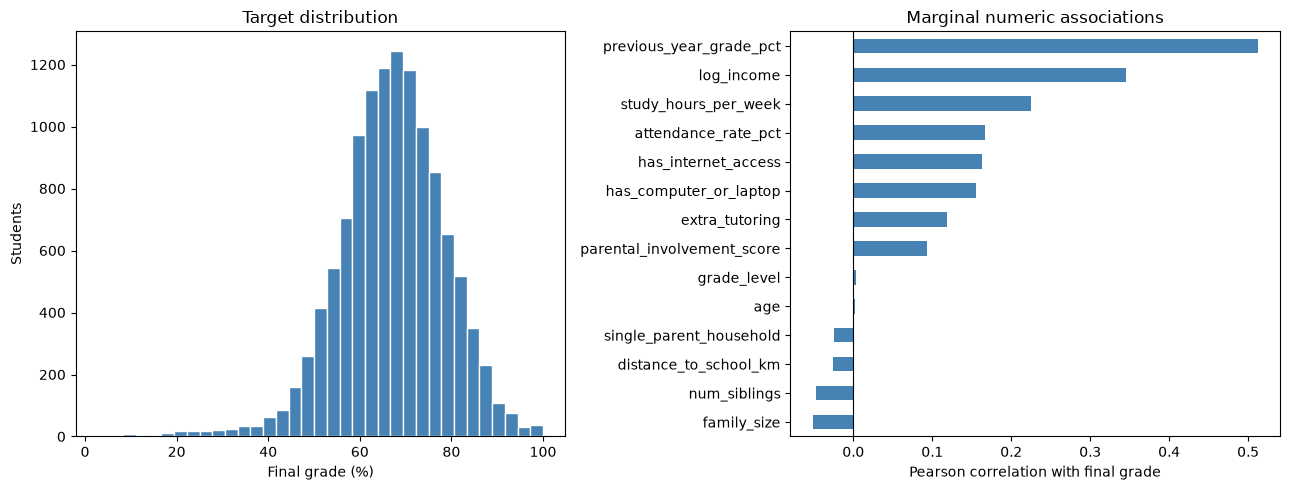

In [14]:
print("Most-missing predictors (fraction of students):")
print(X.isna().mean().sort_values(ascending=False).head(10).round(3).to_string())
print("\nTarget summary:")
print(y.describe().round(2).to_string())

target_corr = X[NUMERIC_COLS].corrwith(y).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(y, bins=35, color="steelblue", edgecolor="white")
axes[0].set(xlabel="Final grade (%)", ylabel="Students", title="Target distribution")
target_corr.plot.barh(ax=axes[1], color="steelblue")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set(xlabel="Pearson correlation with final grade",
            title="Marginal numeric associations")
plt.tight_layout()
plt.show()


## Split and model-specific preprocessing

Keep the same stratified 85/15 split as Project.ipynb. For the GAM, each inner or outer training fold supplies its own imputation values and factor-code levels, following Guan-Ming's implementation. Missing distance is filled using the training fold's residence-specific median, with its overall median as a fallback. Other continuous gaps use training-fold medians; factor gaps use training-fold modes. Unseen validation factor levels use the training mode.

The fixed-settings forest reference retains Project.ipynb's train-partition imputation and one-hot encoding. Its encoded columns are aligned between training and test partitions. Because this forest preprocessing precedes CV, its validation scores may be somewhat optimistic.


In [15]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=df["grade_class"],
    random_state=SEED,
)
print("Training:", X_train_raw.shape, "| test:", X_test_raw.shape)

# Keep Project.ipynb's one-hot representation for the forest reference only.
X_train_forest = X_train_raw.copy()
X_test_forest = X_test_raw.copy()
medians = X_train_forest[NUMERIC_COLS].median()
modes = X_train_forest[CATEGORICAL_COLS].mode().iloc[0]
for X_part in (X_train_forest, X_test_forest):
    X_part[NUMERIC_COLS] = X_part[NUMERIC_COLS].fillna(medians)
    X_part[CATEGORICAL_COLS] = X_part[CATEGORICAL_COLS].fillna(modes)
ref_cols = [f"{col}_{sorted(X_train_forest[col].unique())[0]}"
            for col in CATEGORICAL_COLS]
X_train_forest = pd.get_dummies(
    X_train_forest, columns=CATEGORICAL_COLS, dtype=float
).drop(columns=ref_cols)
X_test_forest = pd.get_dummies(
    X_test_forest, columns=CATEGORICAL_COLS, dtype=float
).reindex(columns=X_train_forest.columns, fill_value=0.0)
assert X_train_forest.notna().all().all() and X_test_forest.notna().all().all()
assert X_test_forest.columns.equals(X_train_forest.columns)
print("Forest columns:", X_train_forest.shape[1])

def prepare_gam_fold(X_fit_raw, X_valid_raw):
    """Fit Guan-Ming's imputation and factor coding on X_fit_raw only."""
    X_fit = X_fit_raw[PREDICTOR_COLS].copy()
    X_valid = X_valid_raw[PREDICTOR_COLS].copy()
    levels_by_feature = {}

    distance_col = "distance_to_school_km"
    distance_by_residence = X_fit.groupby("residence_type")[distance_col].median()
    overall_distance_median = X_fit[distance_col].median()
    for part in (X_fit, X_valid):
        missing = part[distance_col].isna()
        part.loc[missing, distance_col] = (
            part.loc[missing, "residence_type"].map(distance_by_residence)
        )
        part[distance_col] = part[distance_col].fillna(overall_distance_median)

    other_continuous = [col for col in CONTINUOUS_COLS if col != distance_col]
    continuous_medians = X_fit[other_continuous].median()
    X_fit[other_continuous] = X_fit[other_continuous].fillna(continuous_medians)
    X_valid[other_continuous] = X_valid[other_continuous].fillna(continuous_medians)

    for col in DISCRETE_COLS + CATEGORICAL_COLS:
        mode = X_fit[col].mode(dropna=True).iloc[0]
        X_fit[col] = X_fit[col].fillna(mode)
        X_valid[col] = X_valid[col].fillna(mode)
        levels = list(pd.unique(X_fit[col]))
        levels_by_feature[col] = levels
        X_valid[col] = X_valid[col].where(X_valid[col].isin(levels), mode)
        X_fit[col] = pd.Categorical(X_fit[col], categories=levels).codes
        X_valid[col] = pd.Categorical(X_valid[col], categories=levels).codes

    assert X_fit.notna().all().all() and X_valid.notna().all().all()
    return (X_fit.astype(float).to_numpy(),
            X_valid.astype(float).to_numpy(), levels_by_feature)

def make_gam(lambda_s, lambda_f):
    terms = None
    penalties = []
    for index in range(len(PREDICTOR_COLS)):
        is_continuous = index < len(CONTINUOUS_COLS)
        term = s(index, n_splines=10) if is_continuous else f(index)
        terms = term if terms is None else terms + term
        penalties.append(lambda_s if is_continuous else lambda_f)
    return LinearGAM(terms, lam=penalties, max_iter=100, tol=1e-4)

Training: (10200, 22) | test: (1800, 22)
Forest columns: 47


## Tune spline and factor penalties inside cross-validation

The five `s()` splines share **λₛ**, which controls smoothness, while the 17 `f()` factors share **λ𝒻**, which shrinks category effects. Both are positive and chosen jointly by the **lowest mean validation RMSE**. Start with six values from 0.1 to 10,000 for each penalty. If either selected value is at its current grid boundary, search that dimension once more with a wider, sparser five-value grid; retain all previous scores. The inner folds and their fitted preprocessing remain the same across both stages. If the final choice still lies on a searched boundary, report that limitation rather than treating it as an exact optimum.

In [16]:
def choose_lambdas(X_fit_raw, y_fit):
    inner = KFold(n_splits=INNER_SPLITS, shuffle=True, random_state=SEED)
    prepared_folds = []
    for fit_idx, valid_idx in inner.split(X_fit_raw):
        X_inner_fit = X_fit_raw.iloc[fit_idx]
        X_inner_valid = X_fit_raw.iloc[valid_idx]
        y_inner_fit = y_fit.iloc[fit_idx].to_numpy()
        y_inner_valid = y_fit.iloc[valid_idx].to_numpy()
        Z_fit, Z_valid, _ = prepare_gam_fold(X_inner_fit, X_inner_valid)
        prepared_folds.append((Z_fit, Z_valid, y_inner_fit, y_inner_valid))

    rows = []
    evaluated = set()

    def evaluate(grid_s, grid_f):
        for lambda_s in grid_s:
            for lambda_f in grid_f:
                key = (float(lambda_s), float(lambda_f))
                if key in evaluated:
                    continue
                train_errors, valid_errors = [], []
                for Z_fit, Z_valid, y_fit_fold, y_valid_fold in prepared_folds:
                    model = make_gam(*key).fit(Z_fit, y_fit_fold)
                    train_errors.append(root_mean_squared_error(
                        y_fit_fold, model.predict(Z_fit)))
                    valid_errors.append(root_mean_squared_error(
                        y_valid_fold, model.predict(Z_valid)))
                rows.append({"lambda_s": key[0], "lambda_f": key[1],
                             "mean_train_rmse": np.mean(train_errors),
                             "mean_rmse": np.mean(valid_errors),
                             "se_rmse": np.std(valid_errors, ddof=1) / np.sqrt(INNER_SPLITS)})
                evaluated.add(key)

    grid_s = BASE_LAMBDA_GRID
    grid_f = BASE_LAMBDA_GRID
    expanded_s = expanded_f = False
    evaluate(grid_s, grid_f)
    while True:
        scores = pd.DataFrame(rows)
        best = scores.sort_values(
            ["mean_rmse", "lambda_s", "lambda_f"], kind="stable"
        ).iloc[0]
        widen_s = (not expanded_s and
                   best["lambda_s"] in (grid_s[0], grid_s[-1]))
        widen_f = (not expanded_f and
                   best["lambda_f"] in (grid_f[0], grid_f[-1]))
        if not (widen_s or widen_f):
            break
        if widen_s:
            grid_s = WIDE_LAMBDA_GRID
            expanded_s = True
        if widen_f:
            grid_f = WIDE_LAMBDA_GRID
            expanded_f = True
        evaluate(grid_s, grid_f)

    chosen = (float(best["lambda_s"]), float(best["lambda_f"]))
    search_info = {"expanded_s": expanded_s, "expanded_f": expanded_f,
                   "s_on_boundary": chosen[0] in (grid_s[0], grid_s[-1]),
                   "f_on_boundary": chosen[1] in (grid_f[0], grid_f[-1]),
                   "evaluated_pairs": len(scores)}
    return chosen, scores, search_info

## Paired outer-fold comparison

The GAM, fixed-settings forest, and mean-only baseline use the same five outer validation folds. GAM imputation, factor coding, and lambda selection are fitted within each outer training fold. The forest uses the fixed training-partition encoding described above. Its hyperparameters are shown below; it is a reference, not an optimized forest. Fold training sets overlap, so fold differences are descriptive rather than independent-sample significance tests.


In [17]:
FOREST_SETTINGS = dict(
    n_estimators=120, min_samples_leaf=10, max_features=0.7, n_jobs=-1,
)
outer_cv = KFold(n_splits=OUTER_SPLITS, shuffle=True, random_state=SEED)
cv_rows = []
selected_lambdas = []
outer_search_info = []

for fold, (fit_idx, valid_idx) in enumerate(outer_cv.split(X_train_raw), start=1):
    X_fit_raw, X_valid_raw = X_train_raw.iloc[fit_idx], X_train_raw.iloc[valid_idx]
    y_fit, y_valid = y_train.iloc[fit_idx], y_train.iloc[valid_idx]
    lambdas, _, search_info = choose_lambdas(X_fit_raw, y_fit)
    selected_lambdas.append(lambdas)
    outer_search_info.append(search_info)
    Z_fit, Z_valid, _ = prepare_gam_fold(X_fit_raw, X_valid_raw)
    X_fit_forest = X_train_forest.iloc[fit_idx]
    X_valid_forest = X_train_forest.iloc[valid_idx]
    models_and_features = {
        "Mean only": (DummyRegressor(strategy="mean"), X_fit_forest, X_valid_forest),
        "Random forest (reference)": (
            RandomForestRegressor(**FOREST_SETTINGS, random_state=SEED + fold),
            X_fit_forest, X_valid_forest),
        "GAM": (make_gam(*lambdas), Z_fit, Z_valid),
    }
    for name, (model, fit_features, valid_features) in models_and_features.items():
        model.fit(fit_features, y_fit.to_numpy())
        score = root_mean_squared_error(y_valid, model.predict(valid_features))
        cv_rows.append({"fold": fold, "model": name, "rmse": score})
    print(f"Outer fold {fold}/{OUTER_SPLITS}: "
          f"lambda_s={lambdas[0]:g}, lambda_f={lambdas[1]:g}; "
          f"expanded s={search_info['expanded_s']}, "
          f"f={search_info['expanded_f']}; "
          f"pairs={search_info['evaluated_pairs']}")

cv_scores = pd.DataFrame(cv_rows)
print("\nGAM penalties by outer fold:", selected_lambdas)
print("Boundary search by outer fold:", outer_search_info)

Outer fold 1/5: lambda_s=10000, lambda_f=100; expanded s=True, f=False; pairs=48
Outer fold 2/5: lambda_s=10000, lambda_f=100; expanded s=True, f=False; pairs=48
Outer fold 3/5: lambda_s=10000, lambda_f=100; expanded s=True, f=False; pairs=48
Outer fold 4/5: lambda_s=1000, lambda_f=100; expanded s=False, f=False; pairs=36
Outer fold 5/5: lambda_s=1000, lambda_f=100; expanded s=False, f=False; pairs=36

GAM penalties by outer fold: [(10000.0, 100.0), (10000.0, 100.0), (10000.0, 100.0), (1000.0, 100.0), (1000.0, 100.0)]
Boundary search by outer fold: [{'expanded_s': True, 'expanded_f': False, 's_on_boundary': False, 'f_on_boundary': False, 'evaluated_pairs': 48}, {'expanded_s': True, 'expanded_f': False, 's_on_boundary': False, 'f_on_boundary': False, 'evaluated_pairs': 48}, {'expanded_s': True, 'expanded_f': False, 's_on_boundary': False, 'f_on_boundary': False, 'evaluated_pairs': 48}, {'expanded_s': False, 'expanded_f': False, 's_on_boundary': False, 'f_on_boundary': False, 'evaluated_

                           mean_rmse  sd_rmse
model                                        
GAM                            9.633    0.212
Random forest (reference)      9.835    0.202
Mean only                     11.697    0.090
GAM minus Random forest (reference): mean paired fold RMSE difference = -0.202


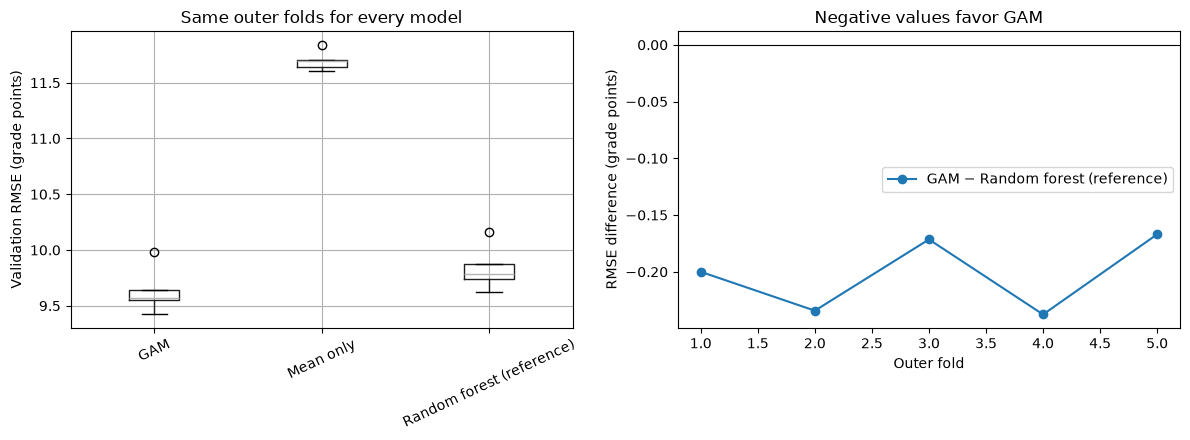

In [25]:
cv_wide = cv_scores.pivot(index="fold", columns="model", values="rmse")
cv_summary = (cv_scores.groupby("model")["rmse"]
              .agg(mean_rmse="mean", sd_rmse="std")
              .sort_values("mean_rmse"))
print(cv_summary.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cv_wide.boxplot(ax=axes[0], rot=25)
axes[0].set(ylabel="Validation RMSE (grade points)",
            title="Same outer folds for every model")
comparators = ["Random forest (reference)"]
for name in comparators:
    diff = cv_wide["GAM"] - cv_wide[name]
    axes[1].plot(diff.index, diff.values, marker="o", label=f"GAM − {name}")
    print(f"GAM minus {name}: mean paired fold RMSE difference = {diff.mean():+.3f}")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(xlabel="Outer fold", ylabel="RMSE difference (grade points)",
            title="Negative values favor GAM")
axes[1].legend()
plt.tight_layout()
plt.show()


## Final fits and the shared test partition

Retune both GAM penalties using training rows only. The next cell stores each evaluated penalty pair and its inner-CV RMSE in `final_inner_scores`, with a pivoted view in `inner_cv_rmse_grid`. Rerun the annotated heatmap cell to change its appearance without repeating the inner CV. Then refit each model on all training rows. The test partition is scored once per final model in this notebook. Because Project.ipynb already used this partition, report these scores as corroboration, not untouched confirmatory evidence.

In [26]:
final_lambdas, final_inner_scores, final_search_info = choose_lambdas(
    X_train_raw, y_train)
final_lambda_s, final_lambda_f = final_lambdas
print("Full-training inner-CV scores (best 15 pairs):")
print(final_inner_scores.sort_values("mean_rmse").head(15).round(3).to_string(index=False))
print(f"Chosen GAM penalties: lambda_s={final_lambda_s:g}, "
      f"lambda_f={final_lambda_f:g}")
print("Boundary search:", final_search_info)
# Rows are spline penalties; columns are factor penalties.
inner_cv_rmse_grid = final_inner_scores.pivot(
    index="lambda_s", columns="lambda_f", values="mean_rmse")


Full-training inner-CV scores (best 15 pairs):
 lambda_s  lambda_f  mean_train_rmse  mean_rmse  se_rmse
   1000.0     100.0            9.554      9.632    0.096
  10000.0     100.0            9.558      9.632    0.095
    100.0     100.0            9.551      9.636    0.097
  10000.0      10.0            9.552      9.637    0.096
   1000.0      10.0            9.549      9.637    0.097
  10000.0       1.0            9.551      9.641    0.097
   1000.0       1.0            9.548      9.641    0.097
    100.0      10.0            9.545      9.641    0.097
     10.0     100.0            9.547      9.642    0.097
  10000.0       0.1            9.551      9.642    0.097
   1000.0       0.1            9.548      9.642    0.097
    100.0       1.0            9.544      9.645    0.098
    100.0       0.1            9.544      9.646    0.098
     10.0      10.0            9.541      9.647    0.097
      1.0     100.0            9.543      9.649    0.096
Chosen GAM penalties: lambda_s=1000, lamb

NameError: name 'Rectangle' is not defined

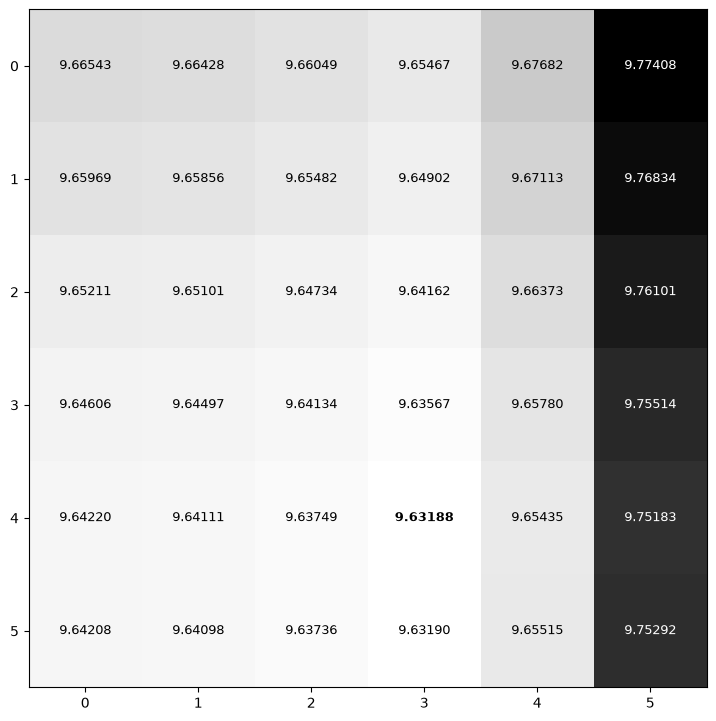

In [37]:
# Rows are spline penalties; columns are factor penalties.
rmse_values = inner_cv_rmse_grid.to_numpy(dtype=float)
s_lambdas = inner_cv_rmse_grid.index.to_numpy()
f_lambdas = inner_cv_rmse_grid.columns.to_numpy()
selected_row = inner_cv_rmse_grid.index.get_loc(final_lambda_s)
selected_col = inner_cv_rmse_grid.columns.get_loc(final_lambda_f)

cmap = plt.get_cmap("Greys").copy()
cmap.set_bad("white")  # Unevaluated pairs may occur after a boundary expansion.
fig, ax = plt.subplots(
    figsize=(max(9, 1.1 * len(f_lambdas) + 2),
             max(7, 0.85 * len(s_lambdas) + 2)),
    layout="constrained")
image = ax.imshow(np.ma.masked_invalid(rmse_values), cmap=cmap)

for (row, col), value in np.ndenumerate(rmse_values):
    if np.isnan(value):
        label, text_color = "N/A", "black"
    else:
        label = f"{value:.5f}"
        red, green, blue = image.cmap(image.norm(value))[:3]
        luminance = 0.2126 * red + 0.7152 * green + 0.0722 * blue
        text_color = "white" if luminance < 0.45 else "black"
    ax.text(col, row, label, ha="center", va="center", color=text_color,
            fontsize=9, fontweight="bold" if (row, col) ==
            (selected_row, selected_col) else "normal")

ax.add_patch(Rectangle((selected_col - 0.5, selected_row - 0.5), 1, 1,
                       fill=False, edgecolor="black", linewidth=2.5))
ax.set_xticks(np.arange(len(f_lambdas)), [f"{value:g}" for value in f_lambdas])
ax.set_yticks(np.arange(len(s_lambdas)), [f"{value:g}" for value in s_lambdas])
ax.set_xticks(np.arange(-0.5, len(f_lambdas), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(s_lambdas), 1), minor=True)
ax.grid(which="minor", color="0.7", linewidth=0.8)
ax.tick_params(which="minor", bottom=False, left=False)
ax.set_xlabel("Factor penalty (lambda_f)")
ax.set_ylabel("Spline penalty (lambda_s)")
ax.set_title("Inner-CV RMSE across GAM penalty pairs\n"
             "Outlined cell = selected minimum; darker = higher RMSE")
plt.show()


In [30]:
Z_train, Z_test, final_category_levels = prepare_gam_fold(X_train_raw, X_test_raw)
final_models = {
    "Mean only": DummyRegressor(strategy="mean").fit(
        X_train_forest, y_train.to_numpy()),
    "Random forest (reference)": RandomForestRegressor(
        **FOREST_SETTINGS, random_state=SEED).fit(
            X_train_forest, y_train.to_numpy()),
    "GAM": make_gam(*final_lambdas).fit(Z_train, y_train.to_numpy()),
}
test_predictions = {
    "Mean only": final_models["Mean only"].predict(X_test_forest),
    "Random forest (reference)": final_models["Random forest (reference)"].predict(X_test_forest),
    "GAM": final_models["GAM"].predict(Z_test),
}
test_rmse = pd.Series({
    name: root_mean_squared_error(y_test, pred)
    for name, pred in test_predictions.items()
}, name="test_rmse").sort_values()
print("\nTest RMSE (grade points):")
print(test_rmse.round(3).to_string())
gam_final = final_models["GAM"]
smooth_edf = pd.Series({
    name: gam_final.statistics_["edof_per_coef"][
        gam_final.terms.get_coef_indices(i)].sum()
    for i, name in enumerate(CONTINUOUS_COLS)
}, name="effective degrees of freedom")
print("\nApproximate effective degrees of freedom by smooth:")
print(smooth_edf.round(2).to_string())


Test RMSE (grade points):
GAM                           9.832
Random forest (reference)    10.038
Mean only                    11.708

Approximate effective degrees of freedom by smooth:
distance_to_school_km      2.71
study_hours_per_week       1.58
attendance_rate_pct        2.17
previous_year_grade_pct    1.86
log_income                 2.09


### Paired uncertainty on test performance

The interval below resamples test **students** while holding the fitted GAM and forest fixed. It describes uncertainty in their paired RMSE difference on this test population. It does not include uncertainty from retraining, tuning, or having previously inspected this same test set. A negative GAM-minus-forest difference favors the GAM.


                                 rmse_difference  ci_lower  ci_upper
comparison                                                          
GAM − Random forest (reference)           -0.205    -0.295     -0.11


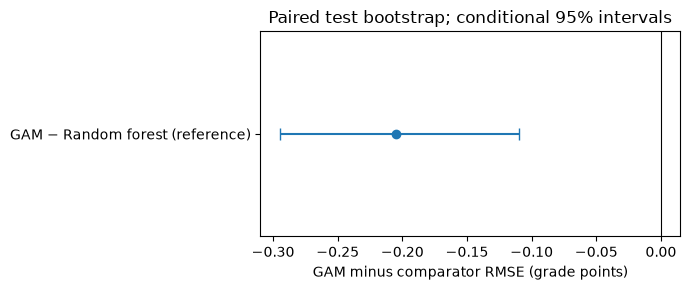

In [31]:
rng = np.random.default_rng(SEED)
test_y = y_test.to_numpy()
bootstrap_index = rng.integers(0, len(test_y), size=(1000, len(test_y)))
gam_squared_error = (test_y - test_predictions["GAM"]) ** 2

comparison_rows = []
for name in ["Random forest (reference)"]:
    comparator_squared_error = (test_y - test_predictions[name]) ** 2
    boot_diff = (
        np.sqrt(gam_squared_error[bootstrap_index].mean(axis=1))
        - np.sqrt(comparator_squared_error[bootstrap_index].mean(axis=1))
    )
    comparison_rows.append({
        "comparison": f"GAM − {name}",
        "rmse_difference": test_rmse["GAM"] - test_rmse[name],
        "ci_lower": np.quantile(boot_diff, 0.025),
        "ci_upper": np.quantile(boot_diff, 0.975),
    })
comparison = pd.DataFrame(comparison_rows).set_index("comparison")
print(comparison.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 3))
positions = np.arange(len(comparison))
ax.errorbar(
    comparison["rmse_difference"], positions,
    xerr=[comparison["rmse_difference"] - comparison["ci_lower"],
          comparison["ci_upper"] - comparison["rmse_difference"]],
    fmt="o", capsize=4,
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(positions, comparison.index)
ax.set(xlabel="GAM minus comparator RMSE (grade points)",
       title="Paired test bootstrap; conditional 95% intervals")
plt.tight_layout()
plt.show()


## Partial dependence plots

The plots show the selected GAM's five continuous smooth terms on the grade-point scale, with approximate **pointwise 95% model-based confidence limits** from PyGAM. These are fitted-effect intervals, not intervals for individual grades or evidence of causality. Each horizontal range is restricted to the middle 90% of training values. PyGAM term effects include a vertical offset relative to the intercept, so interpret the shape and change across each x-axis.


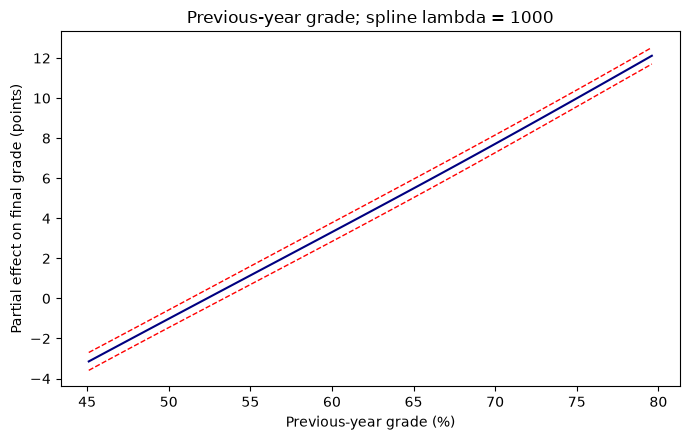

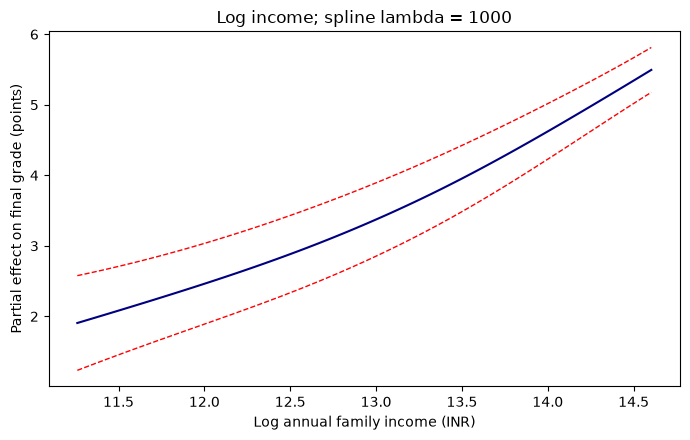

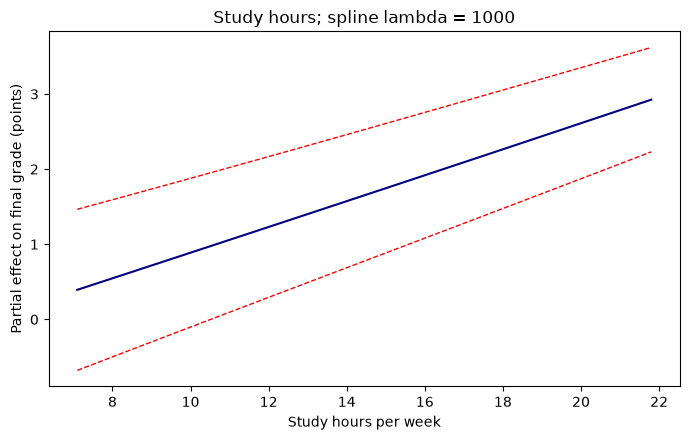

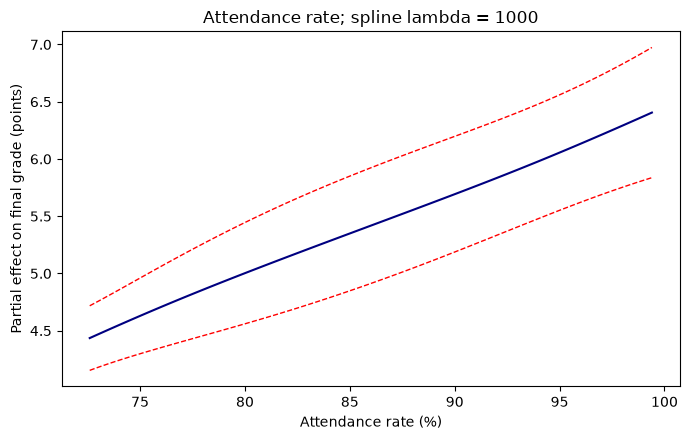

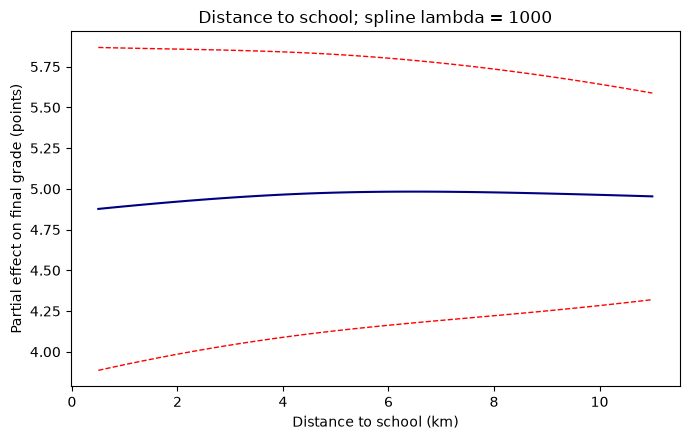

In [32]:
PLOT_SMOOTHS = [
    "previous_year_grade_pct", "log_income",
    "study_hours_per_week", "attendance_rate_pct",
    "distance_to_school_km",
]
axis_labels = {
    "previous_year_grade_pct": "Previous-year grade (%)",
    "log_income": "Log annual family income (INR)",
    "study_hours_per_week": "Study hours per week",
    "attendance_rate_pct": "Attendance rate (%)",
    "distance_to_school_km": "Distance to school (km)",
}
term_labels = {
    "previous_year_grade_pct": "previous-year grade",
    "log_income": "log income",
    "study_hours_per_week": "study hours",
    "attendance_rate_pct": "attendance rate",
    "distance_to_school_km": "distance to school",
}
base_row = Z_train[0].copy()
for term_index in range(len(CONTINUOUS_COLS)):
    base_row[term_index] = np.median(Z_train[:, term_index])

for name in PLOT_SMOOTHS:
    term_index = CONTINUOUS_COLS.index(name)
    lo, hi = np.quantile(Z_train[:, term_index], [0.05, 0.95])
    grid = np.tile(base_row, (120, 1))
    grid[:, term_index] = np.linspace(lo, hi, len(grid))
    effect, interval = gam_final.partial_dependence(
        term=term_index, X=grid, width=0.95)
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(grid[:, term_index], effect, color="navy")
    ax.plot(grid[:, term_index], interval, color="red",
            linestyle="--", linewidth=1)
    ax.set(xlabel=axis_labels[name],
           ylabel=f"Partial effect on final grade (points)",
           title=(f"{term_labels[name].capitalize()}; "
                  f"spline lambda = {final_lambda_s:g}"))
    fig.tight_layout()
    plt.show()

### An adjusted categorical contrast

For scholarship status, set the raw category to each observed level for the **same** sampled training students, apply the final training-fitted GAM encoding, and average the GAM predictions. Additivity makes these level differences constant across students, but the adjusted averaging states clearly what is being compared. Report prediction differences in grade points, not causal effects.


In [35]:
scholarship_levels = sorted(X_train_raw["scholarship_status"].dropna().unique())
template = X_train_raw.sample(n=min(1000, len(X_train_raw)), random_state=SEED).copy()
adjusted_predictions = {}
for level in scholarship_levels:
    changed = template.copy()
    changed["scholarship_status"] = level
    _, Z_changed, _ = prepare_gam_fold(X_train_raw, changed)
    adjusted_predictions[level] = gam_final.predict(Z_changed).mean()
reference_level = scholarship_levels[0]
scholarship_effects = pd.Series({
    level: value - adjusted_predictions[reference_level]
    for level, value in adjusted_predictions.items()
}, name=f"predicted grade difference vs {reference_level} (points)")
print(scholarship_effects.round(3).to_string())


Full              0.000
No Scholarship   -3.289
Partial          -1.764


## Diagnostics and report interpretation

A residual pattern can reveal structure the additive model misses. Use the CV and test tables, smooth plots, and limitations together:

- Compare the GAM with the fixed forest and mean-only baseline using paired RMSE differences and their practical size.
- A forest advantage could reflect interactions or other flexibility. These models alone cannot isolate the cause.
- Report the selected spline and factor penalties separately, including whether either search reached a boundary.
- The forest is a fixed reference, outer-fold training sets overlap, its encoding is prepared before CV, and the shared test set has already been examined in the main notebook.
- Keep the report concise. Check the rubric separately for its unsupervised-analysis criterion.

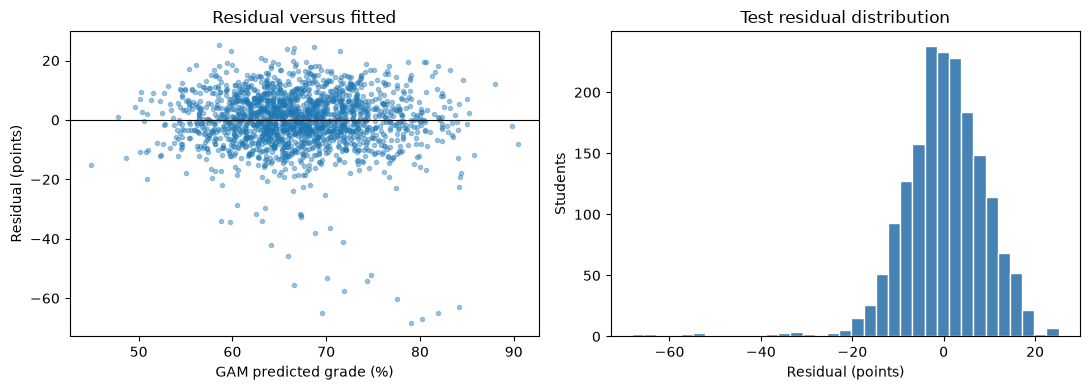

Mean test residual: -0.127 points


In [36]:
gam_residual = test_y - test_predictions["GAM"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(test_predictions["GAM"], gam_residual, s=9, alpha=0.4)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set(xlabel="GAM predicted grade (%)", ylabel="Residual (points)",
            title="Residual versus fitted")
axes[1].hist(gam_residual, bins=35, color="steelblue", edgecolor="white")
axes[1].set(xlabel="Residual (points)", ylabel="Students",
            title="Test residual distribution")
plt.tight_layout()
plt.show()
print(f"Mean test residual: {gam_residual.mean():+.3f} points")


## Findings from the verified run

The GAM uses Guan-Ming's five spline terms and 17 factor terms, with separate penalties selected jointly by the lowest inner-CV mean RMSE. On the full training partition, **spline λₛ = 1,000** and **factor λ𝒻 = 100** were selected from 36 candidate pairs, with inner-CV RMSE **9.632 grade points**. The pair (10,000, 100) also rounds to 9.632, so the evidence does not establish a meaningful difference between these spline penalties. Across the five outer folds, λ𝒻 = 100 every time; λₛ = 10,000 in three folds and 1,000 in two. The wider spline search was triggered in the first three folds, and no final selected penalty was at its searched grid boundary. These grid results are not proof of an exact global optimum.

Across five paired outer folds, the GAM has mean RMSE **9.633 grade points**, the fixed-settings forest **9.835**, and the mean-only baseline **11.697**. The GAM-minus-forest paired fold difference averages **−0.202** points. On the shared test partition, GAM RMSE is **9.832**, forest RMSE **10.038**, and mean-only RMSE **11.708**. A paired bootstrap of test students gives a GAM-minus-forest RMSE difference of **−0.205** points with a conditional 95% interval of **[−0.295, −0.110]**. This interval holds both fitted models fixed, and the test set was already inspected in Project.ipynb.

The five fitted smooths use roughly **1.6 to 2.7 effective degrees of freedom**. These are adjusted, model-based effects, not marginal correlations or causal effects. The model assumes additivity and treats the nine integer-coded discrete predictors as unordered factors. The forest is a fixed reference and uses train-partition preprocessing before CV, which may make its CV score optimistic. Re-run the notebook if the data, feature choices, or environment changes.
